
# Credit Card Fraud Detection — Exploratory Data Analysis

## Project Objective
Analyze credit card transaction data to identify fraud patterns, examine transaction amounts, and understand differences across spending categories.

## Dataset Overview
- Total transactions: 389,002
- Fraudulent transactions: 2,252
- Fraud rate: approximately 0.58%
- Tools: Python, Pandas, Matplotlib, and Seaborn

## Analysis Workflow
1. Load and inspect the dataset.
2. Check data quality and missing values.
3. Analyze transaction amount distributions.
4. Compare fraudulent and non-fraudulent transactions.
5. Examine monthly transaction trends.
6. Identify categories with higher fraud rates.

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load data
df = pd.read_csv("cc_data.csv")
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"], format="%d-%m-%Y %H:%M")

In [3]:
# 1) Dimensions
print(df.shape)

(389002, 23)


In [4]:
# 2) Unique values in categoricals
categorical_cols = ["merchant","category","gender","state","city","job"]
for c in categorical_cols:
    print(c, df[c].nunique())

merchant 693
category 14
gender 2
state 51
city 890
job 492


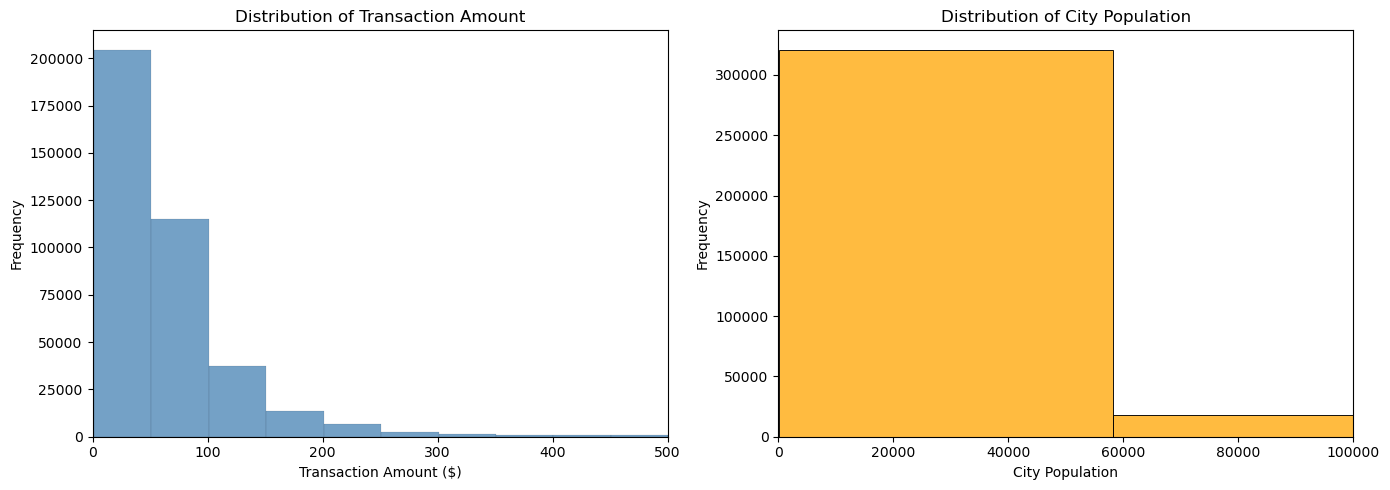

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Transaction amount
sns.histplot(
    data=df,
    x="amt",
    binwidth=50,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_xlim(0, 500)
axes[0].set_title("Distribution of Transaction Amount")
axes[0].set_xlabel("Transaction Amount ($)")
axes[0].set_ylabel("Frequency")

# City population
sns.histplot(
    data=df,
    x="city_pop",
    bins=50,
    ax=axes[1],
    color="orange"
)
axes[1].set_xlim(0, 100000)
axes[1].set_title("Distribution of City Population")
axes[1].set_xlabel("City Population")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [7]:
# 4) Missing values
print(df.isna().sum().sort_values(ascending=False).head(10))

index         0
zip           0
merch_long    0
merch_lat     0
unix_time     0
trans_num     0
dob           0
job           0
city_pop      0
long          0
dtype: int64


In [8]:
# 5) Summary statistics
print(df[num_cols].describe())

                 amt      city_pop
count  389002.000000  3.890020e+05
mean       70.442148  8.868084e+04
std       162.203915  3.012101e+05
min         1.000000  2.300000e+01
25%         9.660000  7.430000e+02
50%        47.570000  2.456000e+03
75%        83.077500  2.032800e+04
max     27390.120000  2.906700e+06


In [9]:
# 6) Correlation between numerical variables
print(df[num_cols].corr())

               amt  city_pop
amt       1.000000  0.007271
city_pop  0.007271  1.000000


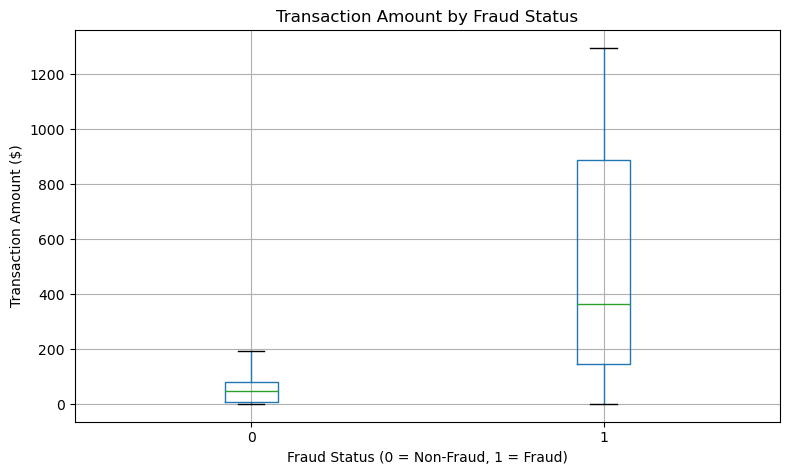

In [11]:
import matplotlib.pyplot as plt

ax = df.boxplot(
    column="amt",
    by="is_fraud",
    showfliers=False,
    figsize=(8, 5)
)

ax.set_title("Transaction Amount by Fraud Status")
ax.set_xlabel("Fraud Status (0 = Non-Fraud, 1 = Fraud)")
ax.set_ylabel("Transaction Amount ($)")

plt.suptitle("")
plt.tight_layout()
plt.show()

In [12]:
df.groupby("is_fraud")["amt"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
is_fraud,,,,,,
0,386750,67.83,47.33,156.23,1.00,27390.12
1,2252,518.33,365.28,389.13,1.18,1294.83


In [13]:
# 8) Outliers in city_pop and amt (IQR method example)
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    return lower, upper
for c in ["amt","city_pop"]:
    lo, hi = iqr_outliers(df[c])
    print(c, lo, hi)

amt -100.46625 193.20375
city_pop -28634.5 49705.5


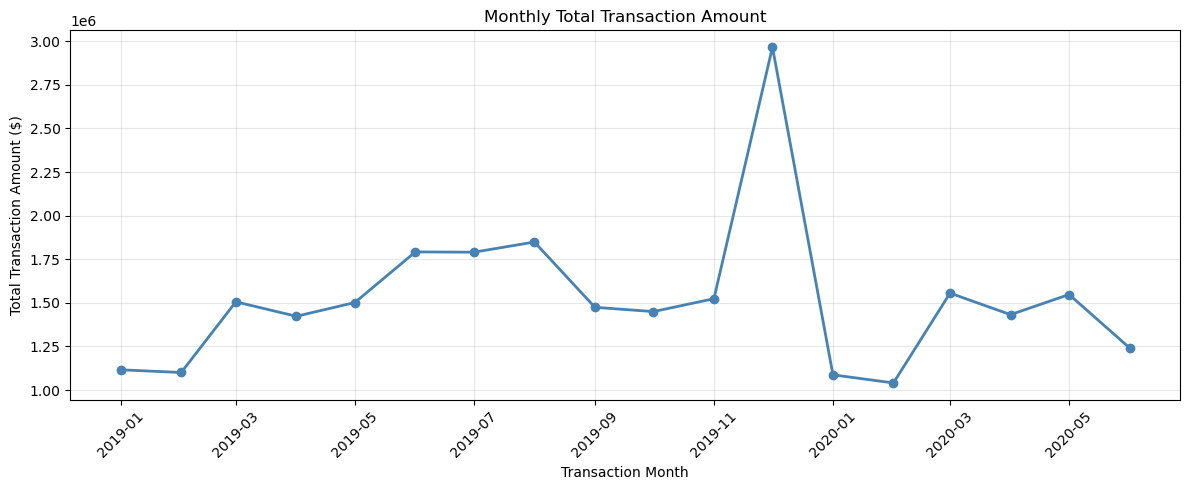

In [15]:
import matplotlib.pyplot as plt

# Convert transaction dates to monthly periods
df["month"] = df["trans_date_trans_time"].dt.to_period("M").dt.to_timestamp()

# Calculate monthly transaction totals
monthly = df.groupby("month")["amt"].sum()

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly.index,
    monthly.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.title("Monthly Total Transaction Amount")
plt.xlabel("Transaction Month")
plt.ylabel("Total Transaction Amount ($)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [17]:
fraud_rate_by_cat = (
    df.groupby("category")["is_fraud"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(fraud_rate_by_cat.head(10).round(2))

category
shopping_net     1.63
misc_net         1.50
grocery_pos      1.41
shopping_pos     0.72
gas_transport    0.49
travel           0.34
misc_pos         0.32
grocery_net      0.29
personal_care    0.28
entertainment    0.24
Name: is_fraud, dtype: float64



## Key Findings and Business Recommendations

### 1. Fraud Is Relatively Rare
Out of 389,002 transactions, 2,252 were labeled fraudulent, representing approximately 0.58% of all transactions.

**Business recommendation:** Monitor fraud rates alongside transaction volumes because fraud represents a small proportion of overall activity.

### 2. Transaction Amounts Differ by Fraud Status
The transaction amount analysis compares fraudulent and non-fraudulent transactions using summary statistics and box plots.

**Business recommendation:** Investigate unusual transaction amounts in combination with other indicators rather than relying on transaction value alone.

### 3. Fraud Rates Vary Across Categories
The highest observed fraud rates include:
- Shopping online (`shopping_net`): 1.63%
- Miscellaneous online (`misc_net`): 1.50%
- Grocery point-of-sale (`grocery_pos`): 1.41%

**Business recommendation:** Prioritize category-specific monitoring and review higher-risk transaction patterns.

### 4. Transaction Activity Changes Over Time
Monthly transaction amounts fluctuate across the observed period.

**Business recommendation:** Monitor changes in transaction value and volume to help identify unusual activity.

## Conclusion
This exploratory analysis highlights differences in transaction amounts, fraud prevalence, and category-level fraud rates. These findings can support fraud monitoring and further investigation, but the project does not build or evaluate a predictive fraud detection model.